##### Introduction to Artificial Intelligence
## Lab 07 Tasks
This lab covers adversial searches

#### Adversial Searches

**Lab Outcomes**
* Explain adversarial search and the role of competing agents.
* Represent a game as a search tree.
* Implement Minimax to determine the best possible move.
* Alpha-Beta Pruning to skip unnecessary branches.
* Compare the number of nodes explored by both algorithms.

**Exercise:** \
A game AI must choose between three possible moves. Each move leads to an opponent's decision node, followed by three possible outcomes. Your task is to implement Alpha-Beta Pruning and compare its performance with Minimax.

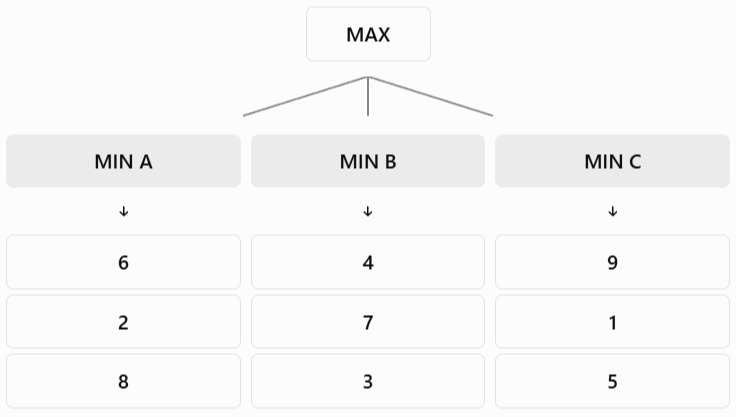

In [2]:
game_tree = {
    "MIN A": [6, 2, 8],
    "MIN B": [4, 7, 3],
    "MIN C": [9, 1, 5]
}

nodes_visited = 0

def minimax(node, is_maximizing):
    global nodes_visited
    nodes_visited += 1

    if isinstance(node, int):
        print(f"Evaluating leaf: {node}")
        return node

    if is_maximizing:
        value = float("-inf")
        for child in node:
            child_value = minimax(child, False)
            value = max(value, child_value)
        print(f"MAX returns: {value}")
        return value

    else:
        value = float("inf")
        for child in node:
            child_value = minimax(child, True)
            value = min(value, child_value)
        print(f"MIN returns: {value}")
        return value

best_move = None
best_score = float("-inf")
alpha = float("-inf")
beta = float("inf")

for move, children in game_tree.items():
    print(f"\nExploring move {move}")
    score = minimax(children, False)
    print(f"Move {move} has value {score}")

    if score > best_score:
        best_score = score
        best_move = move

print("\n----- MINIMAX FINAL RESULT -----")
print("Best move:", best_move)
print("Best score:", best_score)
print("Total nodes visited:", nodes_visited)


Exploring move MIN A
Evaluating leaf: 6
Evaluating leaf: 2
Evaluating leaf: 8
MIN returns: 2
Move MIN A has value 2

Exploring move MIN B
Evaluating leaf: 4
Evaluating leaf: 7
Evaluating leaf: 3
MIN returns: 3
Move MIN B has value 3

Exploring move MIN C
Evaluating leaf: 9
Evaluating leaf: 1
Evaluating leaf: 5
MIN returns: 1
Move MIN C has value 1

----- MINIMAX FINAL RESULT -----
Best move: MIN B
Best score: 3
Total nodes visited: 12


**Exercise:**
A robot is exploring a treasure cave. It can choose one of three paths: A, B or C. Each path leads to two possible outcomes depending on the cave guardian's response.
The robot wants to collect the highest treasure score (MAX), while the guardian tries to reduce the robot's score (MIN).
The scores represent the treasure points the robot would receive at the end of each outcome.
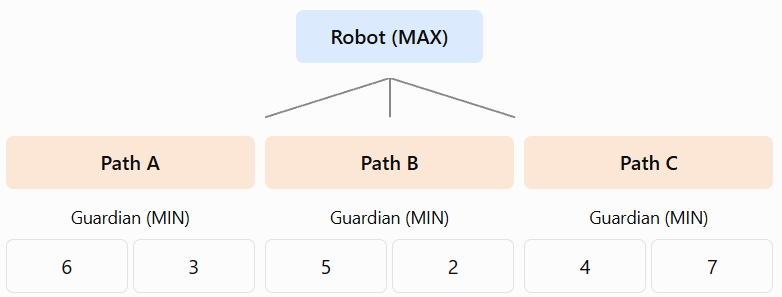

Apply Minimax and alpha-beta Pruning.

In [1]:
game_tree = {
    "MIN A": [6, 2, 8],
    "MIN B": [4, 7, 3],
    "MIN C": [9, 1, 5]
}

nodes_visited = 0

def alpha_beta(node, alpha, beta, is_maximizing):
    global nodes_visited
    nodes_visited += 1

    if isinstance(node, int):
        print(f"Evaluating leaf: {node}")
        return node

    if is_maximizing:
        value = float("-inf")
        for child in node:
            child_value = alpha_beta(child, alpha, beta, False)
            value = max(value, child_value)
            alpha = max(alpha, value)
            if beta <= alpha:
                print("Pruning remaining children at MAX")
                break
        print(f"MAX returns: {value}")
        return value

    else:
        value = float("inf")
        for child in node:
            child_value = alpha_beta(child, alpha, beta, True)
            value = min(value, child_value)
            beta = min(beta, value)
            if beta <= alpha:
                print("Pruning remaining children at MIN")
                break
        print(f"MIN returns: {value}")
        return value

best_move = None
best_score = float("-inf")
alpha = float("-inf")
beta = float("inf")

for move, children in game_tree.items():
    print(f"\nExploring move {move}")
    score = alpha_beta(children, alpha, beta, False)
    print(f"Move {move} has value {score}")

    if score > best_score:
        best_score = score
        best_move = move

    alpha = max(alpha, best_score)

print("\n----- ALPHA-BETA FINAL RESULT -----")
print("Best move:", best_move)
print("Best score:", best_score)
print("Total nodes visited:", nodes_visited)


Exploring move MIN A
Evaluating leaf: 6
Evaluating leaf: 2
Evaluating leaf: 8
MIN returns: 2
Move MIN A has value 2

Exploring move MIN B
Evaluating leaf: 4
Evaluating leaf: 7
Evaluating leaf: 3
MIN returns: 3
Move MIN B has value 3

Exploring move MIN C
Evaluating leaf: 9
Evaluating leaf: 1
Pruning remaining children at MIN
MIN returns: 1
Move MIN C has value 1

----- ALPHA-BETA FINAL RESULT -----
Best move: MIN B
Best score: 3
Total nodes visited: 11


**Marking Criteria** CLO-I \
For each question with marks 20, the marking will be done according to the following criteria. 

| Component | Marks |
| :--- | :---: |
| Correct Minimax implementation | 5 |
| Correct Alpha-Beta implementation | 5 |
| **Total Marks** | 10 |
